# Day 058 | Soil Type Classification (ML)

## 100 Days of ML for Geotechnical Engineering
**Phase:** Classical Machine Learning

**Author:** Ripon Chandra Malo  
**Date:** YYYY-MM-DD  

---

## What We Will Learn Today

| Concept | What It Means | Geotechnical Example |
|---------|--------------|---------------------|
| Multi-class Classification | Predict one of many categories | Classify soil as SW, SP, CL, CH, ML, MH, GP, GW |
| USCS Classification | Unified Soil Classification System | Standard engineering soil taxonomy |
| Confusion Matrix (multi-class) | Which classes get confused with each other | Does model confuse CL with ML? |
| Per-class Metrics | Precision/Recall for each soil type | How well can we identify CH vs CL? |
| Class Imbalance | Some soil types are rarer than others | MH samples may be underrepresented |
| Feature Engineering | Create informative input features | Activity index = PI / clay fraction |

---

## Our Geotechnical Problem

We classify soil samples into **USCS categories** (SW, SP, CL, CH, ML, MH, GP, GW)  
based on index properties: N-value, fines content, water content, liquid limit, plasticity index, specific gravity, and unit weight.

This automates what engineers currently do manually from lab test results.

---

## Part 1: Load and Explore the Dataset

In [1]:
# ─────────────────────────────────────────────────────
# LOAD DATA AND EXPLORATION
# ─────────────────────────────────────────────────────

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('soil_type_classification.csv')

print(f"Dataset shape: {df.shape}")
print(f"\nColumns: {df.columns.tolist()}")
print(f"\nClass distribution:")
print(df['soil_type'].value_counts().sort_index())
print(f"\nDescriptive statistics:")
print(df.describe().round(2))

Dataset shape: (200, 8)

Columns: ['N_value', 'fines_content', 'water_content', 'liquid_limit', 'plasticity_index', 'specific_gravity', 'unit_weight', 'soil_type']

Class distribution:
soil_type
CH    26
CL    25
GP    23
GW    27
MH    17
ML    23
SP    33
SW    26
Name: count, dtype: int64

Descriptive statistics:
       N_value  fines_content  water_content  liquid_limit  plasticity_index  \
count   200.00         200.00         200.00        200.00            200.00   
mean     19.16          36.21          24.04         24.47              8.37   
std      11.63          36.88          16.81         29.60             12.42   
min       2.00           0.00           5.40          0.00              0.00   
25%       9.00           3.10          10.23          0.00              0.00   
50%      17.00           6.65          16.65          0.00              0.00   
75%      27.00          73.50          34.72         45.03             13.95   
max      50.00         101.00          67.

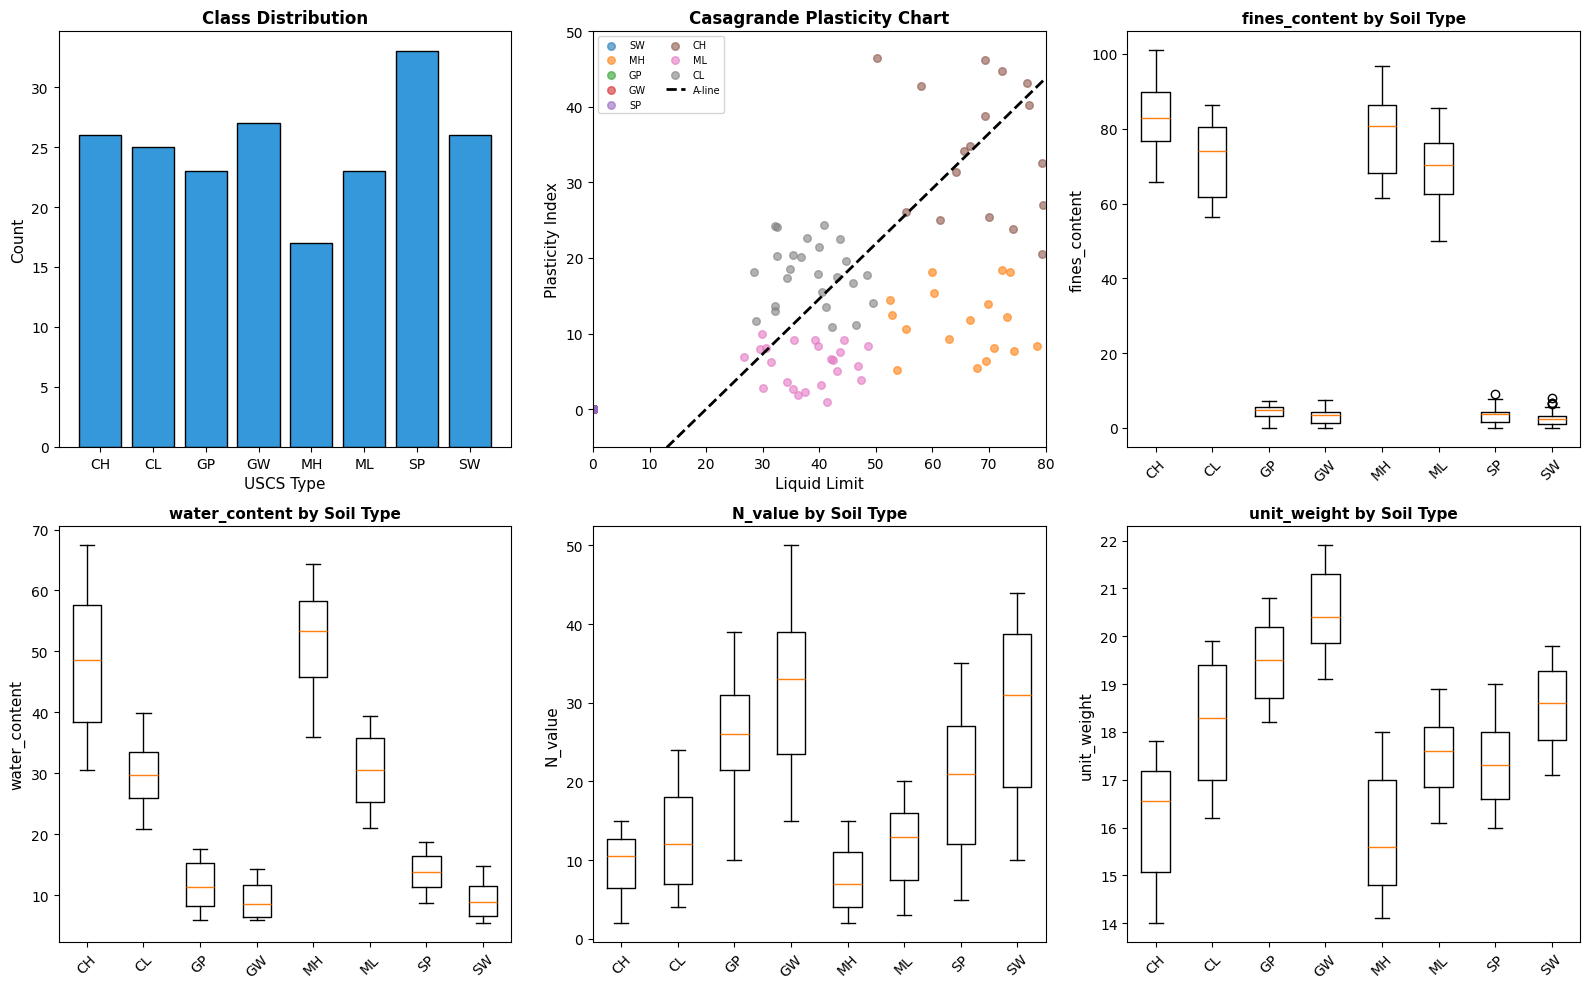

In [2]:
# ─────────────────────────────────────────────────────
# EXPLORATORY PLOTS
# ─────────────────────────────────────────────────────

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# Class distribution
class_counts = df['soil_type'].value_counts().sort_index()
axes[0, 0].bar(class_counts.index, class_counts.values, color='#3498db', edgecolor='black')
axes[0, 0].set_xlabel('USCS Type', fontsize=11)
axes[0, 0].set_ylabel('Count', fontsize=11)
axes[0, 0].set_title('Class Distribution', fontsize=12, fontweight='bold')

# Plasticity chart (Casagrande)
for soil in df['soil_type'].unique():
    mask = df['soil_type'] == soil
    axes[0, 1].scatter(df.loc[mask, 'liquid_limit'], df.loc[mask, 'plasticity_index'],
                        alpha=0.6, s=30, label=soil)
# A-line: PI = 0.73 * (LL - 20)
ll_range = np.linspace(0, 80, 100)
axes[0, 1].plot(ll_range, 0.73 * (ll_range - 20), 'k--', linewidth=2, label='A-line')
axes[0, 1].set_xlabel('Liquid Limit', fontsize=11)
axes[0, 1].set_ylabel('Plasticity Index', fontsize=11)
axes[0, 1].set_title('Casagrande Plasticity Chart', fontsize=12, fontweight='bold')
axes[0, 1].legend(fontsize=7, ncol=2)
axes[0, 1].set_xlim(0, 80)
axes[0, 1].set_ylim(-5, 50)

# Feature distributions by class
for i, feat in enumerate(['fines_content', 'water_content', 'N_value', 'unit_weight']):
    row = (i + 2) // 3
    col = (i + 2) % 3
    soil_types = sorted(df['soil_type'].unique())
    data = [df.loc[df['soil_type'] == s, feat].values for s in soil_types]
    axes[row, col].boxplot(data, labels=soil_types)
    axes[row, col].set_ylabel(feat, fontsize=11)
    axes[row, col].set_title(f'{feat} by Soil Type', fontsize=11, fontweight='bold')
    axes[row, col].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

---

## Part 2: Feature Engineering

In [3]:
# ─────────────────────────────────────────────────────
# FEATURE ENGINEERING — Create informative features
# ─────────────────────────────────────────────────────

# Liquidity index proxy
df['liquidity_proxy'] = np.where(
    df['plasticity_index'] > 0,
    (df['water_content'] - (df['liquid_limit'] - df['plasticity_index'])) / (df['plasticity_index'] + 1e-6),
    0
)

# Is above A-line (for Casagrande classification)
df['above_a_line'] = (df['plasticity_index'] > 0.73 * (df['liquid_limit'] - 20)).astype(int)

# Fines category
df['is_fine_grained'] = (df['fines_content'] > 50).astype(int)

print("Engineered features:")
print(f"  liquidity_proxy: range [{df['liquidity_proxy'].min():.2f}, {df['liquidity_proxy'].max():.2f}]")
print(f"  above_a_line:    {df['above_a_line'].sum()} samples above A-line")
print(f"  is_fine_grained: {df['is_fine_grained'].sum()} fine-grained samples")

features = ['N_value', 'fines_content', 'water_content', 'liquid_limit',
            'plasticity_index', 'specific_gravity', 'unit_weight',
            'liquidity_proxy', 'above_a_line', 'is_fine_grained']
print(f"\nTotal features: {len(features)}")

Engineered features:
  liquidity_proxy: range [-10.30, 2.77]
  above_a_line:    141 samples above A-line
  is_fine_grained: 90 fine-grained samples

Total features: 10


---

## Part 3: Train Multiple Classifiers

In [4]:
# ─────────────────────────────────────────────────────
# TRAIN AND COMPARE CLASSIFIERS
# ─────────────────────────────────────────────────────

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                               AdaBoostClassifier)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score

X = df[features]
le = LabelEncoder()
y = le.fit_transform(df['soil_type'])
class_names = le.classes_

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

classifiers = {
    'Logistic Reg': LogisticRegression(max_iter=2000),  # multinomial by default in sklearn >= 1.5
    'KNN': KNeighborsClassifier(n_neighbors=7),
    'SVM': SVC(kernel='rbf', C=10, gamma='scale'),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=12, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=200, max_depth=5, random_state=42)
}

results = {}
preds = {}
for name, clf in classifiers.items():
    clf.fit(X_train_s, y_train)
    y_pred = clf.predict(X_test_s)
    preds[name] = y_pred
    cv = cross_val_score(clf, X_train_s, y_train, cv=5, scoring='accuracy')
    results[name] = {
        'CV Accuracy': cv.mean(),
        'Test Accuracy': accuracy_score(y_test, y_pred),
        'F1 (macro)': f1_score(y_test, y_pred, average='macro'),
        'F1 (weighted)': f1_score(y_test, y_pred, average='weighted')
    }

results_df = pd.DataFrame(results).T.round(4).sort_values('Test Accuracy', ascending=False)
print("Classifier Comparison:")
print("=" * 65)
print(results_df)

Classifier Comparison:
                   CV Accuracy  Test Accuracy  F1 (macro)  F1 (weighted)
SVM                     0.7188          0.875      0.8736         0.8664
Random Forest           0.7875          0.850      0.8388         0.8316
Logistic Reg            0.7250          0.825      0.8250         0.8150
Gradient Boosting       0.7250          0.825      0.7831         0.7731
KNN                     0.6750          0.725      0.7373         0.7230


---

## Part 4: Confusion Matrix — Which Soils Get Confused?

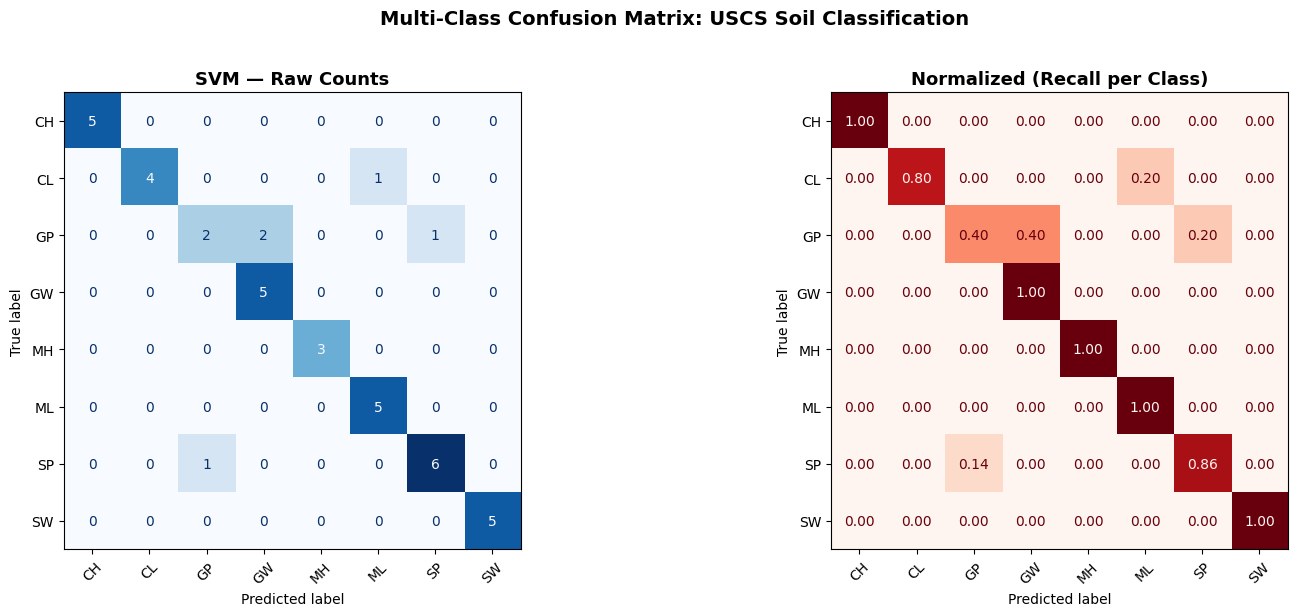

Off-diagonal cells show misclassifications.
Look for: CL<->ML confusion (similar fines, different plasticity)


In [5]:
# ─────────────────────────────────────────────────────
# CONFUSION MATRIX — Multi-class
# ─────────────────────────────────────────────────────

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

best_name = results_df.index[0]
y_pred_best = preds[best_name]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Raw counts
cm = confusion_matrix(y_test, y_pred_best)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=axes[0], cmap='Blues', colorbar=False
)
axes[0].set_title(f'{best_name} — Raw Counts', fontsize=13, fontweight='bold')
axes[0].tick_params(axis='x', rotation=45)

# Normalized (recall per class)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
ConfusionMatrixDisplay(cm_norm, display_labels=class_names).plot(
    ax=axes[1], cmap='Reds', colorbar=False, values_format='.2f'
)
axes[1].set_title('Normalized (Recall per Class)', fontsize=13, fontweight='bold')
axes[1].tick_params(axis='x', rotation=45)

plt.suptitle('Multi-Class Confusion Matrix: USCS Soil Classification',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("Off-diagonal cells show misclassifications.")
print("Look for: CL<->ML confusion (similar fines, different plasticity)")

---

## Part 5: Per-Class Metrics

Classification Report (SVM):
              precision    recall  f1-score   support

          CH       1.00      1.00      1.00         5
          CL       1.00      0.80      0.89         5
          GP       0.67      0.40      0.50         5
          GW       0.71      1.00      0.83         5
          MH       1.00      1.00      1.00         3
          ML       0.83      1.00      0.91         5
          SP       0.86      0.86      0.86         7
          SW       1.00      1.00      1.00         5

    accuracy                           0.88        40
   macro avg       0.88      0.88      0.87        40
weighted avg       0.88      0.88      0.87        40



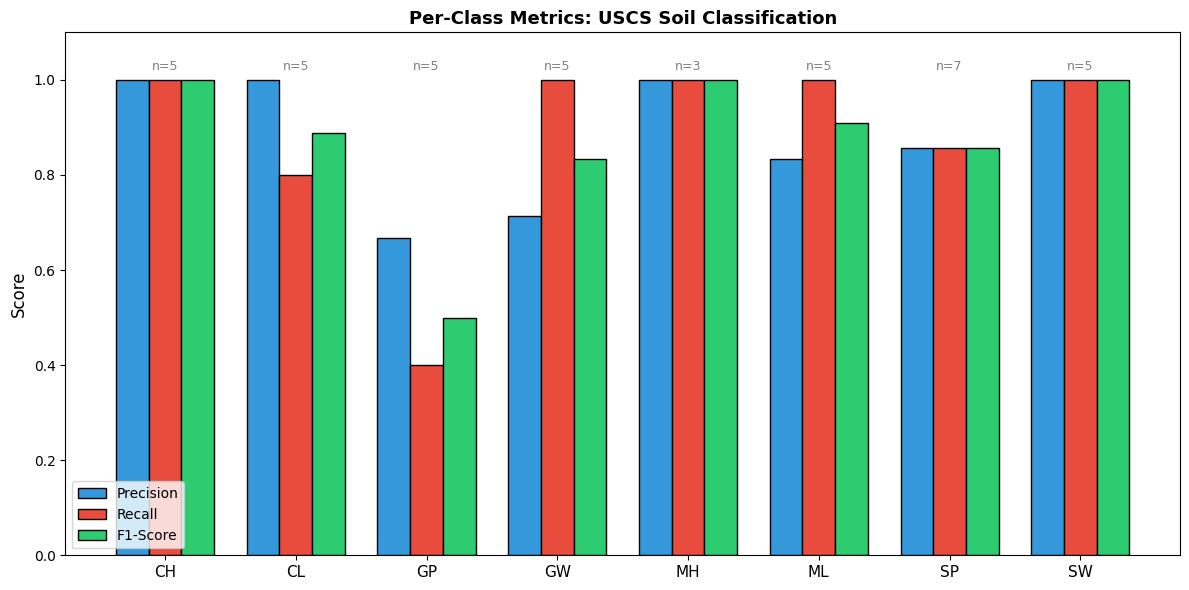

Classes with low recall: model misses those soil types.
Classes with low precision: model over-predicts those types.


In [6]:
# ─────────────────────────────────────────────────────
# PER-CLASS PRECISION, RECALL, F1
# ─────────────────────────────────────────────────────

from sklearn.metrics import classification_report, precision_recall_fscore_support

print(f"Classification Report ({best_name}):")
print("=" * 60)
print(classification_report(y_test, y_pred_best, target_names=class_names))

# Visualize per-class metrics
precision, recall, f1, support = precision_recall_fscore_support(
    y_test, y_pred_best, labels=range(len(class_names))
)

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(class_names))
width = 0.25

ax.bar(x - width, precision, width, label='Precision', color='#3498db', edgecolor='black')
ax.bar(x, recall, width, label='Recall', color='#e74c3c', edgecolor='black')
ax.bar(x + width, f1, width, label='F1-Score', color='#2ecc71', edgecolor='black')

ax.set_xticks(x)
ax.set_xticklabels(class_names, fontsize=11)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Per-Class Metrics: USCS Soil Classification', fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.set_ylim(0, 1.1)

# Add support counts
for i, s in enumerate(support):
    ax.text(i, 1.02, f'n={s}', ha='center', fontsize=9, color='gray')

plt.tight_layout()
plt.show()

print("Classes with low recall: model misses those soil types.")
print("Classes with low precision: model over-predicts those types.")

---

## Part 6: Feature Importance for Classification

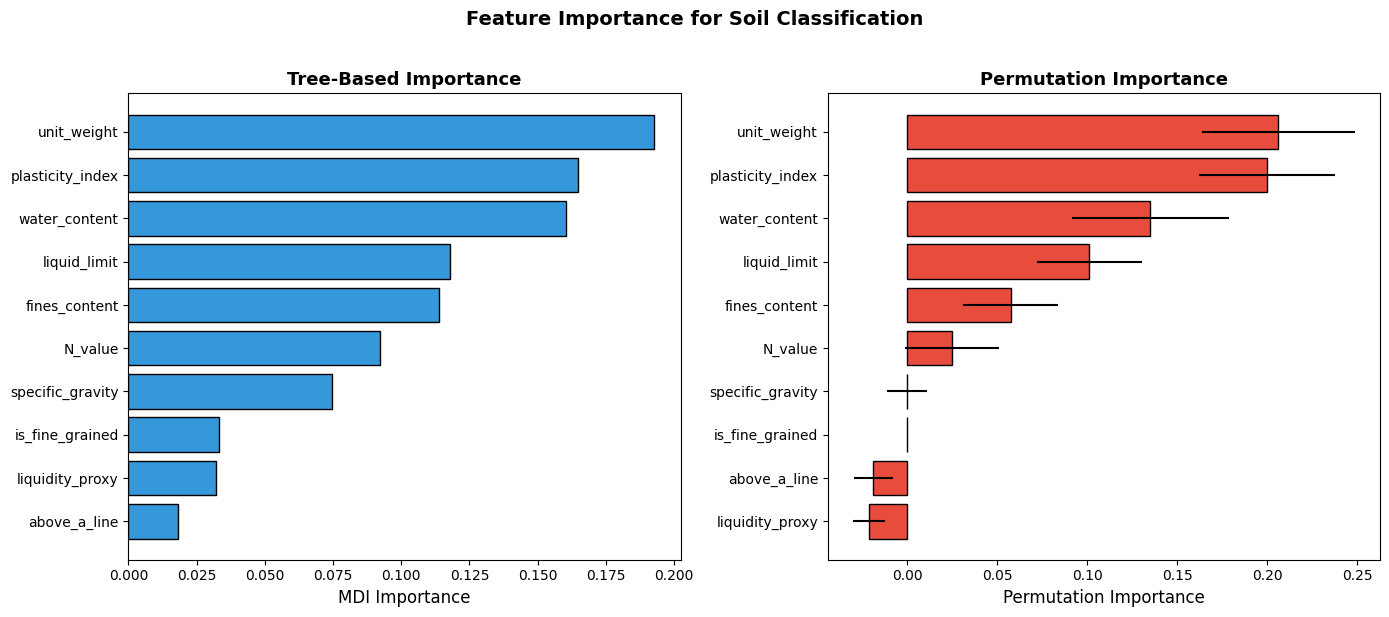

Top features for USCS classification:
  - fines_content:    separates coarse-grained (SW,SP,GP,GW) from fine-grained (CL,CH,ML,MH)
  - plasticity_index: separates C (clay) from M (silt) groups
  - liquid_limit:     separates L (low) from H (high) plasticity


In [7]:
# ─────────────────────────────────────────────────────
# FEATURE IMPORTANCE — Which properties matter most?
# ─────────────────────────────────────────────────────

from sklearn.inspection import permutation_importance

rf_clf = classifiers['Random Forest']
perm = permutation_importance(rf_clf, X_test_s, y_test, n_repeats=20,
                               random_state=42, scoring='accuracy')

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# MDI
sorted_idx = np.argsort(rf_clf.feature_importances_)
axes[0].barh(np.array(features)[sorted_idx], rf_clf.feature_importances_[sorted_idx],
             color='#3498db', edgecolor='black')
axes[0].set_xlabel('MDI Importance', fontsize=12)
axes[0].set_title('Tree-Based Importance', fontsize=13, fontweight='bold')

# Permutation
sorted_perm = np.argsort(perm.importances_mean)
axes[1].barh(np.array(features)[sorted_perm], perm.importances_mean[sorted_perm],
             color='#e74c3c', edgecolor='black',
             xerr=perm.importances_std[sorted_perm])
axes[1].set_xlabel('Permutation Importance', fontsize=12)
axes[1].set_title('Permutation Importance', fontsize=13, fontweight='bold')

plt.suptitle('Feature Importance for Soil Classification',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("Top features for USCS classification:")
print("  - fines_content:    separates coarse-grained (SW,SP,GP,GW) from fine-grained (CL,CH,ML,MH)")
print("  - plasticity_index: separates C (clay) from M (silt) groups")
print("  - liquid_limit:     separates L (low) from H (high) plasticity")

---

## Part 7: Misclassification Analysis

Misclassified: 5/40 (12.5%)

Most common misclassification pairs:
  GP -> GW: 2 samples
  GP -> SP: 1 samples
  CL -> ML: 1 samples
  SP -> GP: 1 samples


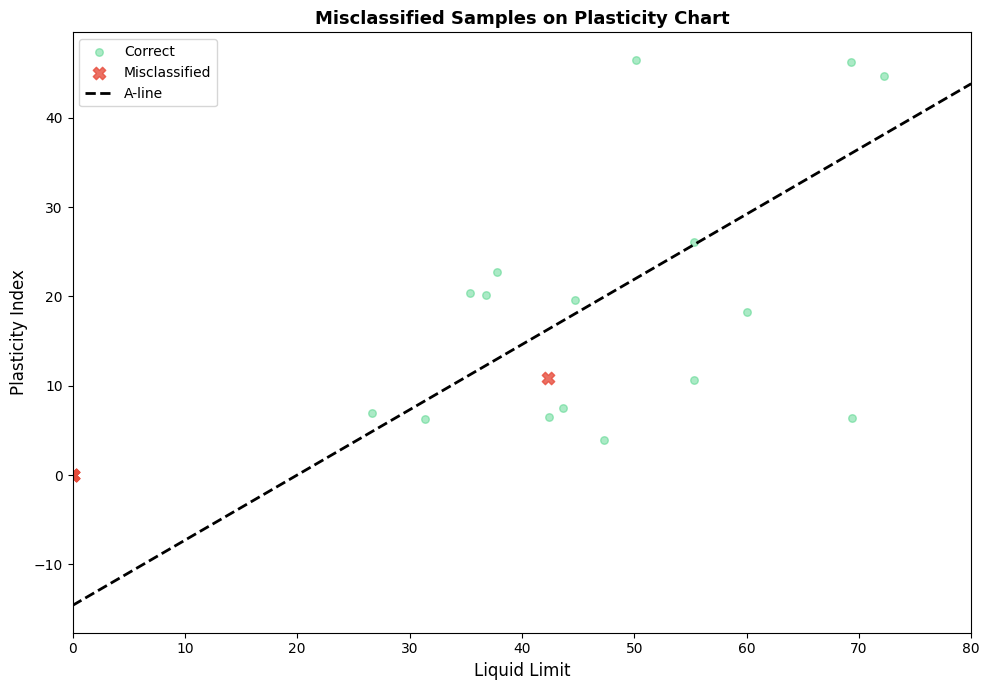


Misclassifications often occur near class boundaries (A-line, LL=50).


In [8]:
# ─────────────────────────────────────────────────────
# MISCLASSIFICATION ANALYSIS — Understand errors
# ─────────────────────────────────────────────────────

# Find misclassified samples
misclassified = y_test != y_pred_best
n_wrong = misclassified.sum()
n_total = len(y_test)

print(f"Misclassified: {n_wrong}/{n_total} ({n_wrong/n_total*100:.1f}%)")
print()

# Show common misclassification pairs
wrong_idx = np.where(misclassified)[0]
confusion_pairs = {}
for idx in wrong_idx:
    true_label = class_names[y_test[idx]]
    pred_label = class_names[y_pred_best[idx]]
    pair = f"{true_label} -> {pred_label}"
    confusion_pairs[pair] = confusion_pairs.get(pair, 0) + 1

print("Most common misclassification pairs:")
for pair, count in sorted(confusion_pairs.items(), key=lambda x: -x[1]):
    print(f"  {pair}: {count} samples")

# Visualize misclassified on plasticity chart
X_test_df = pd.DataFrame(X_test, columns=features)
fig, ax = plt.subplots(figsize=(10, 7))

correct = ~misclassified
ax.scatter(X_test_df.loc[correct, 'liquid_limit'].values,
           X_test_df.loc[correct, 'plasticity_index'].values,
           alpha=0.4, s=30, color='#2ecc71', label='Correct', marker='o')
ax.scatter(X_test_df.loc[misclassified, 'liquid_limit'].values,
           X_test_df.loc[misclassified, 'plasticity_index'].values,
           alpha=0.8, s=80, color='#e74c3c', label='Misclassified', marker='X')

ax.plot(ll_range, 0.73 * (ll_range - 20), 'k--', linewidth=2, label='A-line')
ax.set_xlabel('Liquid Limit', fontsize=12)
ax.set_ylabel('Plasticity Index', fontsize=12)
ax.set_title('Misclassified Samples on Plasticity Chart', fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.set_xlim(0, 80)
plt.tight_layout()
plt.show()

print("\nMisclassifications often occur near class boundaries (A-line, LL=50).")

---

## Part 8: Model Performance Summary

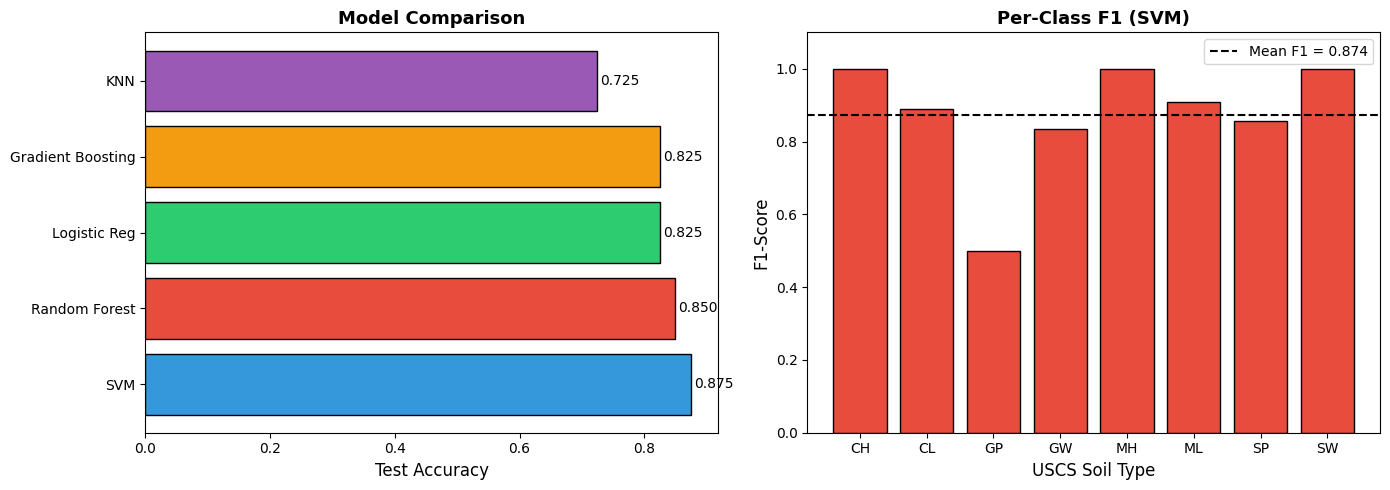


Best model: SVM
  Test Accuracy:  0.8750
  Macro F1:       0.8736
  Weighted F1:    0.8664


In [9]:
# ─────────────────────────────────────────────────────
# COMPREHENSIVE PERFORMANCE SUMMARY
# ─────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Model comparison
colors = ['#3498db', '#e74c3c', '#2ecc71', '#f39c12', '#9b59b6']
axes[0].barh(results_df.index, results_df['Test Accuracy'],
             color=colors[:len(results_df)], edgecolor='black')
axes[0].set_xlabel('Test Accuracy', fontsize=12)
axes[0].set_title('Model Comparison', fontsize=13, fontweight='bold')
for i, (name, row) in enumerate(results_df.iterrows()):
    axes[0].text(row['Test Accuracy'] + 0.005, i,
                 f"{row['Test Accuracy']:.3f}", va='center', fontsize=10)

# F1 by class for best model
axes[1].bar(class_names, f1, color='#e74c3c', edgecolor='black')
axes[1].set_xlabel('USCS Soil Type', fontsize=12)
axes[1].set_ylabel('F1-Score', fontsize=12)
axes[1].set_title(f'Per-Class F1 ({best_name})', fontsize=13, fontweight='bold')
axes[1].axhline(y=np.mean(f1), color='black', linestyle='--',
                label=f'Mean F1 = {np.mean(f1):.3f}')
axes[1].legend(fontsize=10)
axes[1].set_ylim(0, 1.1)

plt.tight_layout()
plt.show()

print(f"\nBest model: {best_name}")
print(f"  Test Accuracy:  {results_df.loc[best_name, 'Test Accuracy']:.4f}")
print(f"  Macro F1:       {results_df.loc[best_name, 'F1 (macro)']:.4f}")
print(f"  Weighted F1:    {results_df.loc[best_name, 'F1 (weighted)']:.4f}")

---

## Practice Exercises

### Exercise 1: Reduce to Coarse/Fine Classification
Group soils into just 2 classes: coarse-grained (S, G) and fine-grained (C, M). How does accuracy change?

### Exercise 2: Handle Class Imbalance
Use `class_weight='balanced'` in RandomForestClassifier. Does it improve recall for minority classes (MH)?

### Exercise 3: Probability Calibration
Get prediction probabilities and examine low-confidence predictions. Do samples with probability < 0.5 tend to be misclassified?

In [10]:
# EXERCISE 1 STARTER:
# coarse = {'SW', 'SP', 'GW', 'GP'}
# df['grain_size'] = df['soil_type'].apply(lambda x: 'Coarse' if x in coarse else 'Fine')
# y_binary = LabelEncoder().fit_transform(df['grain_size'])
# # Split, train, evaluate...
# # Expected: much higher accuracy for binary classification

---

## Key Takeaways

1. **Multi-class classification** for 8 USCS types is harder than binary — more boundaries to learn.

2. **Confusion matrix** reveals which soil types the model confuses — often similar types (CL/ML, SP/SW).

3. **Per-class metrics** are essential: overall accuracy can hide poor performance on rare classes.

4. **Feature engineering** based on domain knowledge (A-line position, fines threshold) improves classification.

5. **Misclassifications concentrate near class boundaries** — exactly where engineers also struggle.

6. For engineering practice, focus on **macro F1** (treats all classes equally) over accuracy.

---

## How This Connects to ML

| Today's Concept | ML Equivalent |
|----------------|---------------|
| USCS soil types | Multi-class labels |
| Casagrande plasticity chart | Feature space decision boundaries |
| Per-class precision/recall | Class-level evaluation |
| Confusion between similar soils | Decision boundary overlap |
| Feature engineering (A-line) | Domain-informed feature creation |
| Class imbalance (rare soil types) | Imbalanced classification problem |

---

*Day 058 of 100 — Teaching machines to classify soil like an engineer!*